# Experiment 1 · Notebook 04: TF-IDF + Logistic Regression: training and evaluation

*J26-IT-304 PP1. Baseline confusion classifier (TF-IDF + Logistic Regression). Sections 8–9.*

Selects hyperparameters by group-aware cross-validation inside the training set, then evaluates the final model on the test set exactly once, against the trivial and length-only baselines.

Section numbers run continuously across the Experiment 1 series, so a reference such as "EDA §3.5" or "section 8" points to the same place in every notebook:

| Notebook | Sections | Stage |
|---|---|---|
| `01_data_and_eda` | §1–§3 | provenance, load, exploratory analysis, leakage demonstration |
| `02_cleaning_and_labels` | §4–§5 | deduplication, group key, label mapping, proxy caveat |
| `03_split_and_baselines` | §6–§7 | group-aware split, trivial baselines, frozen OOD probe |
| `04_model_training_and_evaluation` | §8–§9 | TF-IDF + LR, group-aware CV, the single test evaluation |

Each notebook runs on its own from a clean kernel (kernel `exp1-confusion`). Its first code cell rebuilds its inputs with the same `confusion_baseline` functions the previous stage used, so the stages cannot drift apart. Run them in order 01 → 04 to regenerate every file in `reports/experiments/`.

**Setup.** Imports, and the inputs of this stage: the split from notebook 03 §6, rebuilt and **proved identical** by its fingerprint, and the baseline table that 03 §7 saved.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from confusion_baseline import REPORTS_DIR, SEED
from confusion_baseline.data import load_raw
from confusion_baseline.evaluate import metrics
from confusion_baseline.prep import clean, map_labels
from confusion_baseline.split import group_split, split_fingerprint

pd.set_option("display.width", 200)
plt.rcParams.update({"font.size": 11})
FIG_DIR = REPORTS_DIR / "experiments"

def save_fig(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("saved:", path.relative_to(FIG_DIR.parent.parent).as_posix())
    plt.show()

# Inputs of this stage: the split of notebook 03 (section 6) and its baseline table (section 7).
df, followup_quarantine, _ = load_raw()
del followup_quarantine
y_primary = map_labels(clean(df)[0], "primary")
train, test = group_split(y_primary, test_size=0.2, seed=SEED)

U4_FINGERPRINT = "511fadfecbff1c84dad9f22c4ecdd51052b13c6c1187c6f60d2468342905e44c"
fp = split_fingerprint(test)
assert fp == U4_FINGERPRINT, fp
assert not set(train["group_key"]) & set(test["group_key"])
print(f"PASS: same test set as notebook 03 (fingerprint {fp[:12]}...); train {len(train)} rows / "
      f"{train['group_key'].nunique()} groups, test {len(test)} rows / {test['group_key'].nunique()} groups, 0 shared questions")

baselines = pd.read_csv(FIG_DIR / "baselines_primary.csv")
print("baseline rows from notebook 03:", baselines["System"].tolist())

PASS: same test set as notebook 03 (fingerprint 511fadfecbff...); train 860 rows / 288 groups, test 216 rows / 72 groups, 0 shared questions
baseline rows from notebook 03: ['Majority class', 'Stratified random (seed 42)']


## 8. TF-IDF + Logistic Regression

**Framing (IRWA Lecture 06).** This is a supervised, machine-learning-based text classification task:
labelled examples (answer text, confused / understood) train a classifier that predicts the label of
unseen text. The pipeline is text preprocessing, then **feature extraction**, then a **classifier**, evaluated
with a validation-set approach. Feature extraction turns text into numbers. *Bag of Words* counts how often
each term occurs; *TF-IDF* reweights those counts.

**TF-IDF (L4).**
- *Term frequency* tf(t, d) is the count of term t in document d. *Log-frequency weighting* damps it:
  1 + log(tf) (`sublinear_tf=True`; sklearn uses the natural log).
- *Inverse document frequency* idf(t) = log(N / df(t)) gives rare terms (small df) more weight, because they are
  more informative. The tf-idf weight is the product tf x idf.
- Each document becomes a vector in a |V|-dimensional space (one axis per vocabulary term).
- **L2 length normalisation** divides each vector by its Euclidean norm, so a document "d" and "d appended to
  itself" give the same unit vector (exactly with raw tf; approximately with sublinear tf).

**sklearn's idf differs from the lecture's.** With `smooth_idf=True` (the default) sklearn computes
idf(t) = ln((1 + N) / (1 + df(t))) + 1. Compared with log10(N / df): it uses the natural log (a constant factor
of about 2.3), adds 1 to numerator and denominator (as if one extra document contained every term, which avoids
division by zero), and adds 1 at the end, so a term present in every document gets weight 1 instead of 0.

**The important consequence.** L2 normalisation deliberately removes document length, and EDA section 3.4 showed
that answer length is the strongest simple signal in this data (length-only AUC 0.73-0.75). The TF-IDF model is
therefore **structurally blind to length**. This is why the length-only baseline is in the comparison table.

**Why Logistic Regression.** It is linear, gives probabilistic output, and has interpretable coefficients (one
weight per term), which is the reason to use a lexical baseline at all. Its regularisation strength is C (the
inverse: smaller C = stronger regularisation), which is how Lecture 06 handles over-fitting.

**Rules.** TF-IDF is fitted on training data only, by structure: one `Pipeline` (TfidfVectorizer ->
LogisticRegression), and `fit` is only ever called on training text. All hyperparameter selection uses
cross-validation **inside train** with group-aware folds (`StratifiedGroupKFold`, 5 folds, shuffled, seed 42,
groups = `group_key`); a plain KFold would reintroduce the question leakage the split just closed. The selection
metric is **macro F1**, not F1(confused): the always-confused predictor already gets F1(confused) of about 0.75, so
selecting on it would reward collapsing toward "confused" for everything. The grid is fixed in
`confusion_baseline/model.py` before the first run. The threshold stays at 0.5.

**Why.** Before searching, prove the folds are group-aware: for each of the 5 folds, the validation questions
must be disjoint from that fold's training questions.

In [2]:
from itertools import product
from confusion_baseline.model import PARAM_GRID, N_SPLITS, build_pipeline, cv_folds, cv_search, length_baseline, token_count, save_params

folds = cv_folds(train)
for k, (tr_idx, va_idx) in enumerate(folds, 1):
    overlap = set(train["group_key"].iloc[tr_idx]) & set(train["group_key"].iloc[va_idx])
    assert not overlap, overlap
    print(f"PASS: fold {k}: {len(set(train['group_key'].iloc[tr_idx]))} train groups / "
          f"{len(set(train['group_key'].iloc[va_idx]))} validation groups share 0 questions "
          f"({len(tr_idx)} / {len(va_idx)} rows)")

PASS: fold 1: 229 train groups / 59 validation groups share 0 questions (686 / 174 rows)
PASS: fold 2: 234 train groups / 54 validation groups share 0 questions (687 / 173 rows)
PASS: fold 3: 230 train groups / 58 validation groups share 0 questions (690 / 170 rows)
PASS: fold 4: 232 train groups / 56 validation groups share 0 questions (690 / 170 rows)
PASS: fold 5: 227 train groups / 61 validation groups share 0 questions (687 / 173 rows)


**Why.** The search itself. Every config in the fixed grid is scored on the same 5 group-aware folds, on macro F1
(selection) and F1(confused) (reported). The full results are saved so the choice can be audited.

In [3]:
n_configs = int(np.prod([len(v) for v in PARAM_GRID.values()]))
print("grid size:", n_configs, "configs | folds:", N_SPLITS, "| fits:", n_configs * N_SPLITS, "(+ 1 final refit on all of train)")
search = cv_search(train)

res = pd.DataFrame(search.cv_results_)
# Timing columns (mean_fit_time etc.) change on every run; they are dropped so the saved file is reproducible.
saved = res.drop(columns=[c for c in res.columns if "time" in c])
saved.to_csv(FIG_DIR / "cv_results_primary.csv", index=False)
print("saved: reports/experiments/cv_results_primary.csv", saved.shape, "(timing columns dropped)")

short = {"param_tfidf__ngram_range": "ngram", "param_tfidf__min_df": "min_df", "param_tfidf__stop_words": "stop",
         "param_tfidf__sublinear_tf": "sublinear", "param_clf__C": "C", "param_clf__class_weight": "class_weight",
         "mean_test_macro_f1": "cv macro F1", "std_test_macro_f1": "sd", "mean_test_f1_confused": "cv F1(conf)"}
ranked = res.sort_values("mean_test_macro_f1", ascending=False, kind="stable").reset_index(drop=True)
top10 = ranked.loc[:9, list(short)].rename(columns=short).round(4)
top10[["stop", "class_weight"]] = top10[["stop", "class_weight"]].astype(object).fillna("None")   # None is stored as NaN
top10.index = range(1, 11)
print("\nTop 10 configs by mean CV macro F1 (sd = std over the 5 folds):")
display(top10)

best_mean, best_sd = ranked.loc[0, "mean_test_macro_f1"], ranked.loc[0, "std_test_macro_f1"]
n_within = int((ranked["mean_test_macro_f1"] >= best_mean - best_sd).sum())
print(f"configs within one sd ({best_sd:.4f}) of the best mean ({best_mean:.4f}): {n_within} of {n_configs}")
print(f"worst config mean CV macro F1: {ranked['mean_test_macro_f1'].min():.4f}")

grid size: 160 configs | folds: 5 | fits: 800 (+ 1 final refit on all of train)


saved: reports/experiments/cv_results_primary.csv (160, 23) (timing columns dropped)

Top 10 configs by mean CV macro F1 (sd = std over the 5 folds):


,ngram,min_df,stop,sublinear,C,class_weight,cv macro F1,sd,cv F1(conf)
1,"(1, 2)",1,None,True,100.00,balanced,0.6447,0.0315,0.7353
2,"(1, 2)",2,None,True,1.00,balanced,0.6422,0.0361,0.7143
3,"(1, 2)",1,None,False,1.00,balanced,0.6419,0.0383,0.7176
4,"(1, 2)",2,None,True,10.00,balanced,0.6415,0.0280,0.7257
5,"(1, 2)",1,None,False,10.00,balanced,0.6409,0.0405,0.7257
6,"(1, 1)",2,None,True,10.00,balanced,0.6398,0.0323,0.7159
7,"(1, 2)",1,None,True,1.00,balanced,0.6397,0.0334,0.7180
8,"(1, 2)",1,None,True,10.00,balanced,0.6393,0.0447,0.7274
9,"(1, 2)",2,None,False,1.00,balanced,0.6391,0.0283,0.7049
10,"(1, 2)",2,None,False,0.01,balanced,0.6370,0.0276,0.6974


configs within one sd (0.0315) of the best mean (0.6447): 63 of 160
worst config mean CV macro F1: 0.3800


In [4]:
print("CHOSEN hyperparameters (best mean CV macro F1):")
for k, v in search.best_params_.items():
    print(f"  {k:22s} {v!r}")
print(f"mean CV macro F1 = {search.best_score_:.4f}")

# class_weight question from the spec: best config under each setting
for cw in [None, "balanced"]:
    col_cw = ranked["param_clf__class_weight"]          # grid value None is stored as NaN in cv_results_
    sub = ranked[col_cw.isna() if cw is None else col_cw.eq(cw)]
    print(f"best CV macro F1 with class_weight={cw!r}: {sub['mean_test_macro_f1'].max():.4f}")

save_params(search.best_params_, FIG_DIR / "chosen_params_primary.json",
            selection_metric="macro_f1", cv=f"StratifiedGroupKFold(n_splits={N_SPLITS}, shuffle=True, random_state={SEED}), groups=group_key",
            mean_cv_macro_f1=round(float(search.best_score_), 6), n_configs=n_configs)
print("saved: reports/experiments/chosen_params_primary.json")

CHOSEN hyperparameters (best mean CV macro F1):
  clf__C                 100
  clf__class_weight      'balanced'
  tfidf__min_df          1
  tfidf__ngram_range     (1, 2)
  tfidf__stop_words      None
  tfidf__sublinear_tf    True
mean CV macro F1 = 0.6447
best CV macro F1 with class_weight=None: 0.6352
best CV macro F1 with class_weight='balanced': 0.6447
saved: reports/experiments/chosen_params_primary.json


**Why.** To say *why* each hyperparameter was chosen and whether it matters, this table summarises the CV
results (train folds only; the test set is not involved) one hyperparameter at a time: the best and the average
mean-CV macro F1 over all configs with that value.

In [5]:
res["class_weight"] = res["param_clf__class_weight"].astype(object).fillna("None")
res["stop_words"] = res["param_tfidf__stop_words"].astype(object).fillna("None")
parts = []
for name, c in [("class_weight", "class_weight"), ("C", "param_clf__C"), ("stop_words", "stop_words"),
                ("ngram_range", "param_tfidf__ngram_range"), ("sublinear_tf", "param_tfidf__sublinear_tf"),
                ("min_df", "param_tfidf__min_df")]:
    g = res.groupby(c)["mean_test_macro_f1"].agg(["max", "mean"]).round(4)
    g.index = [f"{name} = {v}" for v in g.index]
    parts.append(g.rename(columns={"max": "best cv macro F1", "mean": "mean over configs"}))
display(pd.concat(parts))

,best cv macro F1,mean over configs
class_weight = None,0.6352,0.4995
class_weight = balanced,0.6447,0.6150
C = 0.01,0.6370,0.4940
C = 0.1,0.6353,0.4949
C = 1.0,0.6422,0.5631
C = 10.0,0.6415,0.6153
C = 100.0,0.6447,0.6190
stop_words = None,0.6447,0.5676
stop_words = english,0.6285,0.5469
"ngram_range = (1, 1)",0.6398,0.5559


**Reading the search.** The chosen configuration is word unigrams + bigrams, `min_df=1`, no stop-word removal,
`sublinear_tf=True`, `C=100`, `class_weight='balanced'`, with mean CV macro F1 = 0.6447 (sd 0.0315 across folds).
**The choice is weakly determined.** The top 10 configs lie within 0.008 of each other, and 63 of the 160 configs are
within one sd of the best, so the winner is not meaningfully better than its neighbours. Taking each hyperparameter in turn:

- **`class_weight` (the spec question "was balancing needed?").** `'balanced'` won, but only narrowly at the top: best
  0.6447 vs 0.6353 for `None`, a difference far smaller than the fold sd. Over the whole grid the gap is large
  (mean 0.615 vs 0.500), because without balancing, strongly regularised models (small C) drift toward predicting
  "confused" for everything and macro F1 collapses toward 0.4. So balancing was **not needed to reach the best
  score, but it protects against that collapse and makes the result robust to C**. It was chosen because it ranked
  first, not because the evidence separates it.
- **`C`.** Large C (weak regularisation) works best on average (C=10 and 100 average 0.615 and 0.619, vs 0.494 for
  C=0.01 and 0.1), but at the top, C=1, 10 and 100 are within 0.003. Small C is clearly worse. Beyond "not too strong",
  the exact value hardly matters.
- **n-grams, `sublinear_tf`, `min_df`, stop words.** These barely matter: bigrams over unigrams gain 0.005 at the
  top, sublinear tf 0.003, and removing stop words costs 0.016 at the best (the stop-word list removes words like
  "not" and "no" that can carry meaning). All differences are well inside one sd.

The honest summary: this model family reaches about 0.64 macro F1 in cross-validation, and tuning moves it by
about 0.01.

## 9. Evaluation

**Why.** Train-set metrics beside cross-validated metrics show over- or under-fitting (Lecture 06): a large gap
with a high train score means the model memorises its training answers. Neither touches the test set.

In [6]:
final = search.best_estimator_            # already refitted on all of train (refit='macro_f1')
train_m = metrics(train["y"], final.predict(train["Answer"]))
i_best = search.best_index_
gap = pd.DataFrame({
    "metric": ["macro F1", "F1 (confused)"],
    "train (refit model)": [train_m["macro_f1"], train_m["f1_confused"]],
    "mean CV (held-out folds)": [res.loc[i_best, "mean_test_macro_f1"], res.loc[i_best, "mean_test_f1_confused"]],
}).round(4)
gap["gap"] = (gap["train (refit model)"] - gap["mean CV (held-out folds)"]).round(4)
display(gap)
print("train metrics, all:", {k: round(v, 4) for k, v in train_m.items()})

,metric,train (refit model),mean CV (held-out folds),gap
0,macro F1,1.0,0.6447,0.3553
1,F1 (confused),1.0,0.7353,0.2647


train metrics, all: {'accuracy': 1.0, 'precision_confused': 1.0, 'recall_confused': 1.0, 'f1_confused': 1.0, 'macro_f1': 1.0}


**Reading the gap.** The refitted model scores a perfect 1.000 on the training set but 0.645 macro F1 and 0.735
F1(confused) on held-out folds: a gap of about 0.36 / 0.26. This is **over-fitting**, as expected for bigrams, weak
regularisation (C=100) and about 860 training answers; the model can memorise its training answers. The CV figure,
not the train figure, is the honest estimate of what the model does on unseen questions. The test result below can be
compared with it: if the test score were far above the CV estimate, that would hint at leakage or luck.

**Why. The test set is touched here, once.** This single cell scores the final refitted pipeline, and the
baselines it is compared against (length-only LR from train; the constant majority predictor), on the 216 test
rows, with threshold 0.5. It then builds the comparison table and a cluster bootstrap. No config is looped over
test, and there is no second look after seeing the number.

**Bootstrap.** 216 rows is small. The bootstrap resamples the 72 test **questions** (groups) with replacement,
1000 times (seed 42), because answers to one question are not independent. It reports 95% percentile intervals for
the model's F1(confused) and macro F1 and for the paired differences model minus majority and model minus
length-only.

TEST metrics, TF-IDF + LR: {'accuracy': 0.6898, 'precision_confused': 0.7095, 'recall_confused': 0.814, 'f1_confused': 0.7581, 'macro_f1': 0.6629}
GATE (rule 6): test F1(confused) = 0.7581 -> not fired (<= 0.90)

classification_report (test, threshold 0.5):
              precision    recall  f1-score   support

  understood     0.6471    0.5057    0.5677        87
    confused     0.7095    0.8140    0.7581       129

    accuracy                         0.6898       216
   macro avg     0.6783    0.6599    0.6629       216
weighted avg     0.6843    0.6898    0.6814       216

confusion matrix, raw counts (rows = actual, cols = predicted):


,pred understood,pred confused
actual understood,44,43
actual confused,24,105


TP = 105 (confused, predicted confused) | FP = 43 (understood, predicted confused) | FN = 24 (confused, predicted understood) | TN = 44 (understood, predicted understood)


saved: reports/experiments/fig_confusion_matrix_primary.png


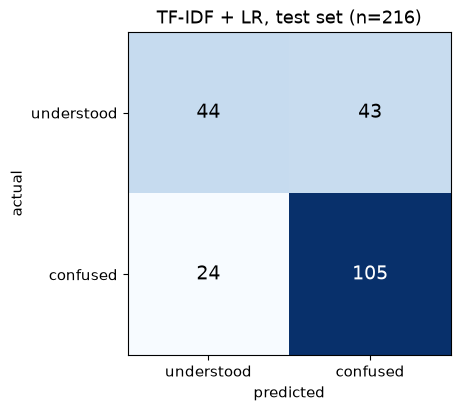


COMPARISON TABLE (test set):


,System,Accuracy,Precision,Recall,F1 (confused),Macro F1
0,Majority class,0.5972,0.5972,1.0000,0.7478,0.3739
1,Stratified random (seed 42),0.4583,0.5441,0.5736,0.5585,0.4289
2,Length-only LR,0.6759,0.6746,0.8837,0.7651,0.6214
3,TF-IDF + LR,0.6898,0.7095,0.8140,0.7581,0.6629


saved: reports/experiments/comparison_primary.csv

Margins (TF-IDF + LR minus ...):
  minus Majority class : F1(confused) +0.0103 | macro F1 +0.2890
  minus Length-only LR : F1(confused) -0.0070 | macro F1 +0.0416



CLUSTER BOOTSTRAP over 72 test questions, 1000 resamples, seed 42; 95% percentile intervals:
  TF-IDF + LR F1 (confused) : point 0.7581   95% CI [0.7102, 0.8090]
  TF-IDF + LR Macro F1      : point 0.6629   95% CI [0.5954, 0.7310]
  difference, model - Majority class  F1 (confused) : point +0.0103   95% CI [-0.0347, +0.0560]  INCLUDES 0
  difference, model - Length-only LR  F1 (confused) : point -0.0070   95% CI [-0.0658, +0.0533]  INCLUDES 0
  difference, model - Majority class  Macro F1      : point +0.2890   95% CI [+0.2215, +0.3559]  EXCLUDES 0
  difference, model - Length-only LR  Macro F1      : point +0.0416   95% CI [-0.0602, +0.1471]  INCLUDES 0


In [7]:
from sklearn.metrics import classification_report, confusion_matrix

# ---- the one and only test-set evaluation ----
pred_model = final.predict(test["Answer"])
len_clf = length_baseline(train)
pred_len = len_clf.predict(token_count(test["Answer"]))
pred_maj = np.ones(len(test), dtype=int)                       # majority class in train = confused
y_te = test["y"].to_numpy()

cols = {"accuracy": "Accuracy", "precision_confused": "Precision", "recall_confused": "Recall",
        "f1_confused": "F1 (confused)", "macro_f1": "Macro F1"}
systems_pred = {"Majority class": pred_maj, "Length-only LR": pred_len, "TF-IDF + LR": pred_model}
m_all = {n: metrics(y_te, p) for n, p in systems_pred.items()}
m = m_all["TF-IDF + LR"]
print("TEST metrics, TF-IDF + LR:", {k: round(v, 4) for k, v in m.items()})
print(f"GATE (rule 6): test F1(confused) = {m['f1_confused']:.4f} -> {'FIRED (> 0.90): stop and run the leakage checklist' if m['f1_confused'] > 0.90 else 'not fired (<= 0.90)'}")

print("\nclassification_report (test, threshold 0.5):")
print(classification_report(y_te, pred_model, target_names=["understood", "confused"], digits=4, zero_division=0))

cm = confusion_matrix(y_te, pred_model, labels=[0, 1])
print("confusion matrix, raw counts (rows = actual, cols = predicted):")
display(pd.DataFrame(cm, index=["actual understood", "actual confused"], columns=["pred understood", "pred confused"]))
tn, fp, fn, tp = (int(x) for x in cm.ravel())
print(f"TP = {tp} (confused, predicted confused) | FP = {fp} (understood, predicted confused) | "
      f"FN = {fn} (confused, predicted understood) | TN = {tn} (understood, predicted understood)")

fig, ax = plt.subplots(figsize=(5, 4.2))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], ["understood", "confused"])
ax.set_yticks([0, 1], ["understood", "confused"])
ax.set_xlabel("predicted")
ax.set_ylabel("actual")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, str(v), ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=14)
ax.set_title("TF-IDF + LR, test set (n=216)")
save_fig(fig, "fig_confusion_matrix_primary.png")

# ---- comparison table: the two Dummy rows come from section 7 (same split, same code) ----
rows = [baselines.iloc[0].to_dict(), baselines.iloc[1].to_dict()]
for n in ["Length-only LR", "TF-IDF + LR"]:
    rows.append({"System": n, **{cols[k]: round(v, 4) for k, v in m_all[n].items()}})
comparison = pd.DataFrame(rows)
order = ["Majority class", "Stratified random (seed 42)", "Length-only LR", "TF-IDF + LR"]
comparison = comparison.set_index("System").loc[order].reset_index()
print("\nCOMPARISON TABLE (test set):")
display(comparison)
comparison.to_csv(FIG_DIR / "comparison_primary.csv", index=False)
print("saved: reports/experiments/comparison_primary.csv")

print("\nMargins (TF-IDF + LR minus ...):")
for base in ["Majority class", "Length-only LR"]:
    print(f"  minus {base:15s}: F1(confused) {m['f1_confused'] - m_all[base]['f1_confused']:+.4f} | "
          f"macro F1 {m['macro_f1'] - m_all[base]['macro_f1']:+.4f}")

# ---- cluster bootstrap over test GROUPS ----
rng = np.random.default_rng(SEED)
g_idx = {g: np.flatnonzero((test["group_key"] == g).to_numpy()) for g in test["group_key"].unique()}
groups_arr = list(g_idx)
boot = {"model": [], "majority": [], "length": []}
for _ in range(1000):
    pick = rng.integers(0, len(groups_arr), len(groups_arr))
    idx = np.concatenate([g_idx[groups_arr[i]] for i in pick])
    for key, pr in [("model", pred_model), ("majority", pred_maj), ("length", pred_len)]:
        boot[key].append(metrics(y_te[idx], pr[idx]))

def col(key, metric):
    return np.array([b[metric] for b in boot[key]])

def ci(a):
    lo, hi = np.percentile(a, [2.5, 97.5])
    return lo, hi

print(f"\nCLUSTER BOOTSTRAP over {len(groups_arr)} test questions, 1000 resamples, seed {SEED}; 95% percentile intervals:")
for metric, label in [("f1_confused", "F1 (confused)"), ("macro_f1", "Macro F1")]:
    lo, hi = ci(col("model", metric))
    print(f"  TF-IDF + LR {label:14s}: point {m[metric]:.4f}   95% CI [{lo:.4f}, {hi:.4f}]")
for metric, label in [("f1_confused", "F1 (confused)"), ("macro_f1", "Macro F1")]:
    for other, name in [("majority", "Majority class"), ("length", "Length-only LR")]:
        d = col("model", metric) - col(other, metric)
        lo, hi = ci(d)
        point = m[metric] - m_all[name][metric]
        verdict = "EXCLUDES 0" if (lo > 0 or hi < 0) else "INCLUDES 0"
        print(f"  difference, model - {name:15s} {label:14s}: point {point:+.4f}   95% CI [{lo:+.4f}, {hi:+.4f}]  {verdict}")

**The result in plain words.** On the 216 held-out answers (72 unseen questions), TF-IDF + Logistic Regression gets
F1(confused) = 0.758, macro F1 = 0.663 and accuracy = 0.690. The gate for suspiciously high scores (> 0.90) did not
fire, and the test macro F1 (0.663) is close to the cross-validated estimate (0.645), so there is no sign of leakage
or an optimistic selection. The model recovers 81% of the confused answers (recall 0.814) but only 51% of the
understood ones (recall 0.506): 43 understood answers are flagged as confused (FP) against 24 confused answers missed
(FN).

**Against the baselines.**
- **vs the majority predictor.** The F1(confused) margin is only **+0.010** (95% CI -0.035 to +0.056, includes 0): the
  model's F1(confused) of 0.758 is not distinguishable from "always confused" (0.748), because that predictor already
  scores high on this class. The **macro F1 margin is +0.289** (CI +0.222 to +0.356, excludes 0): the model really does
  tell the two classes apart, which the constant predictor never does. Accuracy is 0.690 vs 0.597.
- **vs length-only LR.** A logistic regression on **one feature, the number of words**, scores F1(confused) 0.765
  and macro F1 0.621. The TF-IDF model's margin over it is -0.007 on F1(confused) (CI -0.066 to +0.053) and +0.042 on
  macro F1 (CI -0.060 to +0.147): both intervals include 0. **The data cannot show that word content adds anything beyond
  how long the answer is.** This fits the EDA (section 3.4) and the structural point in section 8: TF-IDF is blind to length,
  yet a length-only rule is as good, so most of what separates the classes is shorter answers, which the TF-IDF
  model can only partly pick up through vocabulary.

**What this does and does not show.** It shows that, on this synthetic dataset, a lexical model separates
correct answers from not-fully-correct ones better than the trivial predictors on macro F1, and that it generalises to
unseen questions at roughly its cross-validated level. It does **not** show that confusion detection works: the label
is a correctness proxy, the data has no hedging and no student phrasing, and the lexical model has not been shown to beat
a word-count baseline. With 216 rows, the intervals are wide (macro F1 95% CI 0.595 to 0.731). Coefficients (section 10)
and the out-of-distribution probe (section 11) are the next units, and the probe is where the proxy gap is measured.

## Findings of notebook 04

| Topic | Finding | Where |
|---|---|---|
| Search | 160 configs × 5 group-aware folds, **selected on macro F1**. Chosen: uni+bigrams, min_df 1, no stop words, sublinear tf, C = 100, class_weight balanced. CV macro F1 0.6447 ± 0.0315. The choice is **weakly determined**: the top 10 configs are within 0.008. | §8 |
| Balancing | Not needed to reach the best score (0.6447 vs 0.6353 unweighted), but it prevents strongly regularised models from collapsing to "always confused". | §8 |
| Fit | Train macro F1 1.000 vs CV 0.645: the model memorises the training answers, and the CV/test figures are the honest ones. | §9 |
| **Test** | Accuracy **0.690** · precision 0.710 · recall 0.814 · **F1(confused) 0.758** · **macro F1 0.663**. TP 105 · FP 43 · FN 24 · TN 44. The >0.90 gate did not fire. | §9 |
| vs majority | F1(confused) +0.010, 95% CI [−0.035, +0.056], **not distinguishable**. Macro F1 +0.289 [+0.222, +0.356]: the model **does** separate the classes. | §9 |
| vs length-only | A one-feature word-count model scores F1(confused) 0.765 / macro F1 0.621. Both margins have CIs that include 0, so the data cannot show that word content adds anything beyond answer length. | §9 |
| Not shown | That confusion detection works. The label is a correctness proxy on synthetic data with no student phrasing. The OOD probe (next stage) measures that gap. | §9 |